In [1]:
#install libaries
!pip install -U git+https://github.com/albumentations-team/albumentations
!pip install time

  Cloning https://github.com/albumentations-team/albumentations to /tmp/pip-req-build-9hul5fyq
  Running command git clone --filter=blob:none --quiet https://github.com/albumentations-team/albumentations /tmp/pip-req-build-9hul5fyq
  Resolved https://github.com/albumentations-team/albumentations to commit 66212d77a44927a29d6a0e81621d3c27afbd929c
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Attempting uninstall: albucore
    Found existing installation: albucore 0.0.24
    Uninstalling albucore-0.0.24:
      Successfully uninstalled albucore-0.0.24
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
albumentations 2.0.8 requires albucore==0.0.24, but you have albucore 0.0.28 which is incompatible.
ERROR: Could not find a version that satisfies the requirement time (from versi

In [2]:
#download dataset
!git clone https://github.com/parth1620/object-localization-dataset.git

Cloning into 'object-localization-dataset'...
remote: Enumerating objects: 203, done.
remote: Counting objects: 100% (203/203), done.
remote: Compressing objects: 100% (203/203), done.
remote: Total 203 (delta 3), reused 195 (delta 0), pack-reused 0 (from 0)
Receiving objects: 100% (203/203), 2.73 MiB | 25.00 MiB/s, done.
Resolving deltas: 100% (3/3), done.


In [3]:
import pandas as pd
import numpy as np
import cv2
import matplotlib.pyplot as plt
import torch
from tqdm.notebook import tqdm

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

In [4]:
import sys
sys.path.append('/content/object-localization-dataset')

#configuration

In [5]:
csv_file='/content/object-localization-dataset/train.csv'
data_dir='/content/object-localization-dataset/'

device='cuda'

batch_size=16
img_size=140

Lr=0.001
epcohs=40
model_name='efficentnet_b0'

num_cor=4

In [6]:
df=pd.read_csv(csv_file)
df

,img_path,xmin,ymin,xmax,ymax,width,height,label
0,train_images/mushroom_51.jpg,24,23,202,183,227,227,mushroom
1,train_images/eggplant_37.jpg,34,34,88,201,227,227,eggplant
2,train_images/mushroom_20.jpg,49,86,183,185,227,227,mushroom
3,train_images/eggplant_51.jpg,51,59,191,164,227,227,eggplant
4,train_images/eggplant_26.jpg,40,70,179,168,227,227,eggplant
...,...,...,...,...,...,...,...,...
181,train_images/eggplant_62.jpg,67,22,177,215,227,227,eggplant
182,train_images/cucumber_45.jpg,11,31,217,208,227,227,cucumber
183,train_images/mushroom_37.jpg,93,13,158,193,227,227,mushroom
184,train_images/eggplant_44.jpg,21,59,192,171,227,227,eggplant


#Understand the dataset

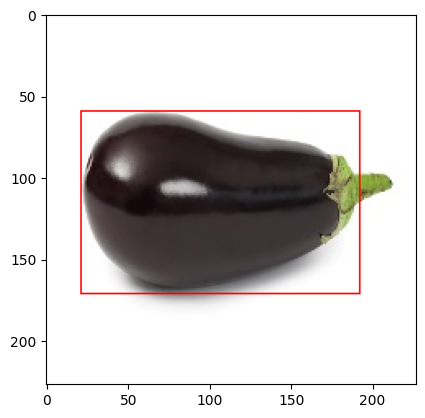

In [12]:
row=df.iloc[184] #
img=cv2.imread(data_dir+row.img_path)
img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB) #form bgr to rgb image
pt1=(row.xmin ,row.ymin)
pt2=(row.xmax,row.ymax)
bnd_box_img=cv2.rectangle(img,pt1,pt2,(255,0,0),1)
plt.imshow(bnd_box_img)

In [13]:
train_df,valid_df=train_test_split(df,test_size=0.20,random_state=42)

#augmentations

In [17]:
import albumentations as A

In [34]:
train_augs=A.Compose([
    A.Resize(img_size,img_size),
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate()
],bbox_params=A.BboxParams(format='pascal_voc',label_fields=['class_labels']))

valid_augs=A.Compose([
    A.Resize(img_size,img_size)
],bbox_params=A.BboxParams(format='pascal_voc',label_fields=['class_labels']))

#Creating dataset

In [35]:
class ObjLocDataset(torch.utils.data.Dataset):

    def __init__(self,df,augmentations=None):
        self.df=df
        self.augmentations=augmentations # Corrected attribute name

    def __len__(self):
        return len(self.df) # Corrected attribute name

    def __getitem__(self,idx):

        row=self.df.iloc[idx]

        xmin=row.xmin
        ymin=row.ymin
        xmax=row.xmax
        ymax=row.ymax

        bbox=[[xmin,ymin,xmax,ymax]]

        img_path=data_dir+row.img_path
        img=cv2.imread(img_path)
        img=cv2.cvtColor(img,cv2.COLOR_BGR2RGB)

        if self.augmentations:
            data=self.augmentations(image=img,bboxes=bbox,class_labels=[None])
            img=data['image']
            bbox=data['bboxes'][0]

        img=torch.from_numpy(img).permute(2,0,1)/255.0 #(h,w,c) =>(c,h,w)
        bbox=torch.Tensor(bbox)

        return img,bbox

In [36]:
trainset=ObjLocDataset(train_df,train_augs)
validset=ObjLocDataset(valid_df,valid_augs)

In [37]:
print(f"Total examples in the trainset: {len(trainset)} ")
print(f"Total examples in the validset: {len(validset)} ")

Total examples in the trainset: 148 
Total examples in the validset: 38 


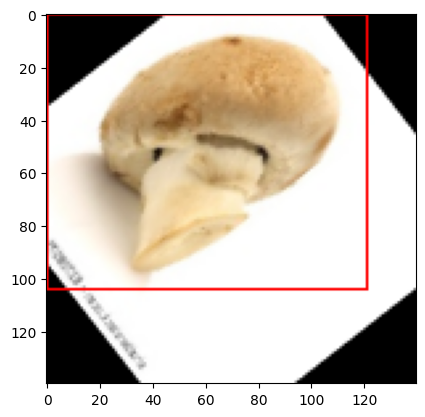

In [41]:
img,bbox=trainset[100]

xmin,ymin,xmax,ymin=bbox

pt1=(int(xmin),int(ymin))
pt2=(int(xmax),int(xmin))

bnd_img=cv2.rectangle(img.permute(1,2,0).numpy(),pt1,pt2,(255,0,0),1)
plt.imshow(bnd_img)

#loaders

#Create model

In [42]:
from torch import nn
import time

In [45]:
from torch import nn
import timm

class objLocModel(nn.Module):

  def __init__(self, model_name='efficientnet_b0', pretrained=True, num_classes=4):
    super(objLocModel,self).__init__()

    self.backbone = timm.create_model(model_name, pretrained=pretrained ,num_classes=num_classes)

  def forward(self,images,gt_bboxes=None):

    bboxes=self.backbone(images)

    if gt_bboxes is not None:
      loss=nn.MSELoss()(bboxes,gt_bboxes)
      return bboxes,loss

    return bboxes

In [46]:
model=objLocModel()
model.to(device)

/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/21.4M [00:00<?, ?B/s]

objLocModel(
  (backbone): EfficientNet(
    (conv_stem): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
    (bn1): BatchNormAct2d(
      32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
      (drop): Identity()
      (act): SiLU(inplace=True)
    )
    (blocks): Sequential(
      (0): Sequential(
        (0): DepthwiseSeparableConv(
          (conv_dw): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
          (bn1): BatchNormAct2d(
            32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True
            (drop): Identity()
            (act): SiLU(inplace=True)
          )
          (aa): Identity()
          (se): SqueezeExcite(
            (conv_reduce): Conv2d(32, 8, kernel_size=(1, 1), stride=(1, 1))
            (act1): SiLU(inplace=True)
            (conv_expand): Conv2d(8, 32, kernel_size=(1, 1), stride=(1, 1))
            (gate): Sigmoid()
          )
          (conv_pw): C

In [49]:
random_img=torch.rand(1,3,140,140).to(device)
model(random_img).shape

torch.Size([1, 4])

#create train and eval function

In [50]:
def train_fn(model,dataloder,optimizer):
  total_loss=0.0
  model.train() #Dropout on

  for data in tqdm(dataloder):

    images,gt_bboxes=data
    images,gt_bboxes=images.to(device),gt_bboxes.to(device)

    bboxes,loss=model(images,gt_bboxes)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    total_loss+=loss.item()

  return total_loss/len(dataloder)

In [51]:
def eval_fn(model,dataloder):
  total_loss=0.0
  model.eval() #Dropout off

  with torch.no_grad():
    for data in tqdm(dataloder):

      images,gt_bboxes=data
      images,gt_bboxes=images.to(device),gt_bboxes.to(device)

      bboxes,loss=model(images,gt_bboxes)

      total_loss+=loss.item()

    return total_loss/len(dataloder)

#loading

In [55]:
from torch.optim import Adam

optimizer = Adam(model.parameters(), lr=Lr)

In [56]:
from torch.utils.data import DataLoader

train_loader = DataLoader(trainset, batch_size=batch_size, shuffle=True)
valid_loader = DataLoader(validset, batch_size=batch_size, shuffle=False)

## Implement training loop

### Subtask:
Write the code for the training loop, including iterating through epochs, calculating loss, backpropagation, and updating model weights.


In [57]:
train_losses = []

for epoch in tqdm(range(epcohs)):
    train_loss = train_fn(model, train_loader, optimizer)
    train_losses.append(train_loss)
    print(f"Epoch: {epoch+1}, Train Loss: {train_loss:.4f}")


  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 1, Train Loss: 5469.0728


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 2, Train Loss: 1933.6715


...

Epoch: 38, Train Loss: 30.7038


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 39, Train Loss: 43.5652


  0%|          | 0/10 [00:00<?, ?it/s]

Epoch: 40, Train Loss: 48.9796


## Implement evaluation loop

### Subtask:
Write the code for the evaluation loop to assess the model's performance on the validation set.


**Reasoning**:
Initialize an empty list to store validation losses and then iterate through epochs, calculate the validation loss, and append it to the list.



In [58]:
valid_losses = []

for epoch in tqdm(range(epcohs)):
    valid_loss = eval_fn(model, valid_loader)
    valid_losses.append(valid_loss)
    print(f"Epoch: {epoch+1}, Valid Loss: {valid_loss:.4f}")

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 1, Valid Loss: 44.2629


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 2, Valid Loss: 44.2629


...

Epoch: 38, Valid Loss: 44.2629


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 39, Valid Loss: 44.2629


  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 40, Valid Loss: 44.2629


## Save best model

### Subtask:
Add logic to save the model's state dictionary when the validation loss improves.


In [59]:
best_valid_loss = float('inf')
train_losses = []
valid_losses = []

for epoch in tqdm(range(epcohs)):
    train_loss = train_fn(model, train_loader, optimizer)
    valid_loss = eval_fn(model, valid_loader)

    train_losses.append(train_loss)
    valid_losses.append(valid_loss)

    print(f"Epoch: {epoch+1}, Train Loss: {train_loss:.4f}, Valid Loss: {valid_loss:.4f}")

    if valid_loss < best_valid_loss:
        best_valid_loss = valid_loss
        torch.save(model.state_dict(), 'best_model.pt')
        print("Saved best model!")

  0%|          | 0/40 [00:00<?, ?it/s]

  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 1, Train Loss: 36.6176, Valid Loss: 38.2192
Saved best model!


  0%|          | 0/10 [00:00<?, ?it/s]

...

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 39, Train Loss: 24.9360, Valid Loss: 43.8209


  0%|          | 0/10 [00:00<?, ?it/s]

  0%|          | 0/3 [00:00<?, ?it/s]

Epoch: 40, Train Loss: 26.6379, Valid Loss: 38.0641


## Load best model

### Subtask:
Modify the inference code to load the saved `best_model.pt` file.


**Reasoning**:
The previous cell failed because the model was not loaded from the saved file. The subtask is to load the saved model state dictionary and set the model to evaluation mode. This can be done in a single code block.



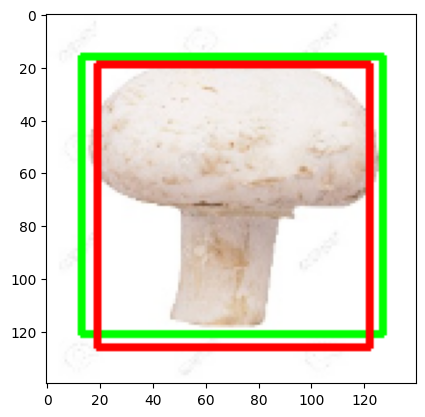

In [60]:
model.load_state_dict(torch.load('best_model.pt'))
model.eval()

with torch.no_grad():

  image,gt_bbox=validset[1] #(c,h,w)
  image=image.unsqueeze(0).to(device) #(bs,c,h,w)
  out_bbox=model(image)

  utils.compare_plots(image, gt_bbox, out_bbox)

## Run inference

### Subtask:
Execute the inference code to test the model with a sample image and visualize the results.


**Reasoning**:
Execute the code to load the best model, perform inference on a sample image from the validation set, and visualize the results using the provided utility function. This directly addresses the subtask requirement.



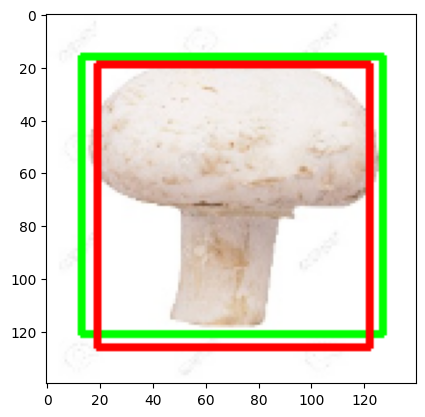

In [61]:
model.load_state_dict(torch.load('best_model.pt'))
model.eval()

with torch.no_grad():

  image,gt_bbox=validset[1] #(c,h,w)
  image=image.unsqueeze(0).to(device) #(bs,c,h,w)
  out_bbox=model(image)

  utils.compare_plots(image, gt_bbox, out_bbox)